<img src="https://drive.google.com/uc?export=view&id=1XMSQvqGXdYM0McNCTafguLUn1uiL8zu_"  width="1500px" height="300px">


# <center> **12. A brief and very preliminary introduction to deep learning!** </center>


This guide uses tf.keras, a high-level API to build and train models in TensorFlow.


##  **Outline**
1. [**DL: The most simple linear model**](#eje1)
2. [**DL: The engineering solution and activation functions**](#eje2)
3. [**DL: Training, Back-propagation and gradient descent**](#eje3)
4. [**DL: Testing: Forward propagation**](#eje4)

In [1]:
#@title 2. LOAD LIB { display-mode: "form" }
#@markdown Here is important to change to GPU

import tensorflow as tf
from tensorflow import keras
print(tf.__version__)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

2.21.0


# **1. DL: The most simple linear model** <a name="eje1"></a>


The **most sucesful** thecnique nowadays is based on the most simple classifier: **the linear classifier!**. The basic idea is to split classes by a linear boundary with dimensions according to the features of the problem.

<img src="https://gitlab.com/bivl2ab/academico/cursos-uis/ai/ai-uis-student/raw/master/2. Notebooks/imgs/img0.png"/>


- It is the most simple classifer, from which the predicted value $\hat{y}$ is represented as a **linear combination** of input variables $\mathbf{X} = [x_1, x_2, \ldots, x_n]$, so:

$$\hat{y}(W, X) = w_0 + x_1 w_1+ x_2 w_2+ \ldots + x_n w_n$$

  - ($x_i$) Inputs: image features, pixels  
  - ($W$) Weights associated to each of the fetures
  - ($\hat{y}$) predictions label. {cat, garfield, car ...}
     
**How?:**

- Fit a linear model with coefficients $w = (w_0, \ldots, w_p)$ minimizing the residual sum of squares:

$$min_{\mathbf{w}} ||\mathbf{X}w -y ||_{2}^{2}$$

**THE PROBLEM NOW IS TO FIND $\mathbf{w}$**

### This linear equation could be represented as a network:


<img src="https://gitlab.com/bivl2ab/academico/cursos-uis/ai/ai-uis-student/raw/master/2. Notebooks/imgs/dl1.jpg" >



Why a relationship with **biological neurons**

<img src="https://gitlab.com/bivl2ab/academico/cursos-uis/ai/ai-uis-student/raw/master/2. Notebooks/imgs/singleN.png" >


**Go to the action!**

## **An example with image classification**

<img src="https://gitlab.com/bivl2ab/academico/cursos-uis/ai/ai-uis-student/raw/master/2. Notebooks/imgs/imageClassification.jpeg" alt="Drawing" style="width:1700px;">

## **MNIST dataset**

The well know classification: MNIST dataset with 60000 images for training and 10000 for test. Images were taken from American Census Bureau employees and American high school students.

**Note:** This original dataset is much larger than previous one!

In [2]:
#@title **code** Download original Mnist
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
print (x_train.shape, y_train.shape, x_test.shape, y_test.shape)
print(tf.__version__)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)
2.21.0


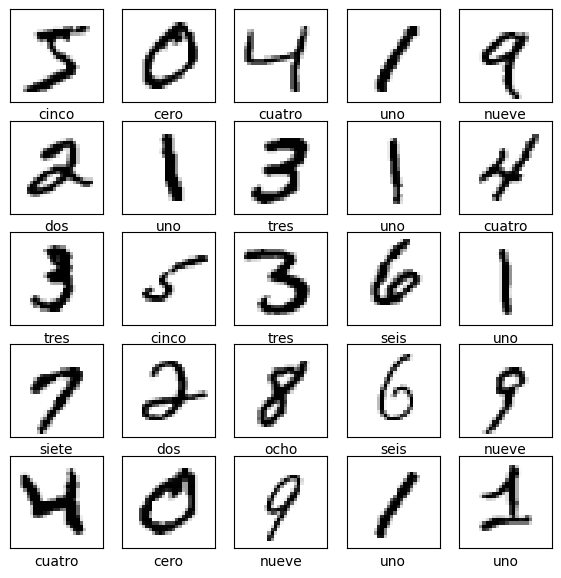

In [3]:
#@title **code** To plot some examples
class_names = ['cero','uno', 'dos', 'tres', 'cuatro', 'cinco', 'seis', 'siete', 'ocho', 'nueve']
plt.figure(figsize=(7,7))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i].reshape(28,28), cmap=plt.cm.binary)
    plt.xlabel(class_names[y_train[i]])

In [4]:
#@title **code** To normalize and prepare data
x_train = x_train.reshape([-1, 28, 28, 1])
x_test = x_test.reshape([-1, 28, 28, 1])

x_train = x_train.astype('float32')
x_test = x_test.astype('float32')

x_train /= 255
x_test /= 255
print('x_train shape:', x_train.shape)
print('Number of images in x_train', x_train.shape[0])
print('Number of images in x_test', x_test.shape[0])

x_train shape: (60000, 28, 28, 1)
Number of images in x_train 60000
Number of images in x_test 10000


# **2. DNN: The engineering solution: hidden layers and activation functions**
<a name="eje2"></a>

<img src="https://gitlab.com/bivl2ab/academico/cursos-uis/ai/ai-uis-student/raw/master/2. Notebooks/imgs/ANNs.gif" style="width:400px;">

<img src="https://gitlab.com/bivl2ab/academico/cursos-uis/ai/ai-uis-student/raw/master/2. Notebooks/imgs/dl2.jpg" style="width:300px;">



## **Main componenets on DNN**


<img src="https://gitlab.com/bivl2ab/academico/cursos-uis/ai/ai-uis-student/raw/master/2. Notebooks/imgs/banner_dl.png" alt="Drawing" style="width:1700px;">


- **input units:**  are raw information as input layer, namely a vectorized version of each sample. For MNIST is a flatten vector of 784 inputs.
- **Hidden units:** are internal correlation on the network, which do the **magic!**. The input units and previous layers are correllated wit some **learned weights**.
- **activation functions:** introduce non-linearity into the output of a neuron. This is important because most real world data is non linear and we want neurons to learn these non linear representations.
    - *Softmax*, used in classification tasks, takes a vector of arbitrary real-valued scores and squashes it to a vector of values between zero and one to ensure that the outputs are probabilities.
    
    
<img src="https://gitlab.com/bivl2ab/academico/cursos-uis/ai/ai-uis-student/raw/master/2. Notebooks/imgs/actifunc.png" >


- **output units** Give the result on correlation of network units, and namelly is mapped to a **sofmax function** to give a probability of each class. On MNIST sample the output layer should be 10 because we have 10 classes.

In [5]:
#@title **code** Coding a DNN from Keras

model = tf.keras.Sequential([
    tf.keras.layers.Flatten( input_shape=[28, 28, 1]),
    tf.keras.layers.Dense(128, activation=tf.nn.relu),
    tf.keras.layers.Dense(10, activation=tf.nn.softmax)
])

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

# **3. DL: Training, Back-propagation and gradient descent** <a name="eje3"></a>

For **training** is used a backpropagation strategy, which consist on compute derivatives from end-to-start into the network. The backpropagation is implemented using a thecnique named **Gradient Descent**, which ‘adjust’ all weights in the network with an aim of reducing the error at the output layer.



- **Backpropagation** best trade-off between intuition and formalism [here](http://home.agh.edu.pl/~vlsi/AI/backp_t_en/backprop.html)


<img src="https://gitlab.com/bivl2ab/academico/cursos-uis/ai/ai-uis-student/raw/master/2. Notebooks/imgs/dl3.gif" >


- **Stochastic gradient descent:**  select randomly a sub-set for training  because the high dimensional problem on DNN
- **Epochs** number of times that an **ENTIRE** dataset is passed orward and backward through the DNN
- **Batch size** is the sub-set of training examples to pass into during gradient descent training. For stochastic gradient descent is used the concep of mini-batch

In [6]:
#@title **code** Training a DNN
model.compile(optimizer=tf.keras.optimizers.SGD(),  #AdamOptimizer(),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model.fit(x_train, y_train, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.8373 - loss: 0.6433
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9076 - loss: 0.3323
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9198 - loss: 0.2850
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9283 - loss: 0.2555
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9351 - loss: 0.2334


# **4. DL: Testing: Forward propagation** <a name="eje4"></a>

Once we have trained our DNN, we follow a classical evaluation of a machine learning dataset. In such case we will to evaluate the accuracy:

In [7]:
#@title **code** Evaluating the model
test_loss, test_acc = model.evaluate(x_test, y_test)

print('Test accuracy:', test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9391 - loss: 0.2162
Test accuracy: 0.9391000270843506


see more deeply on predictions

In [8]:
#@title **code** How work predictions?
predictions = model.predict(x_test)
print(predictions[5125])
print("valor predicho:",  np.argmax(predictions[5125]), "max prob: ", np.max(predictions[5125]),
      "ground truth: ", y_test[5125] )

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
[2.7605511e-05 1.8641193e-06 9.9891198e-01 1.6764544e-04 3.2443992e-07
 3.4299799e-05 4.1323921e-05 1.9222036e-06 8.0584857e-04 7.2584799e-06]
valor predicho: 2 max prob:  0.998912 ground truth:  2


Now, we can evaluate single examples, even new examples

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 418ms/step
the number predicted is:  2


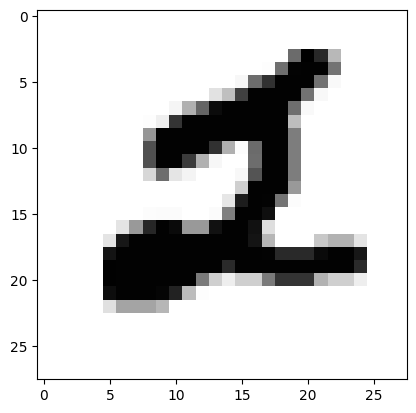

In [9]:
#@title **code** individual predictions
img_rows, img_cols =28, 28
image_index = 5125
plt.imshow(x_test[image_index].reshape(28, 28),cmap='Greys')
pred = model.predict(x_test[image_index].reshape(1, img_rows, img_cols, 1))
print("the number predicted is: ", pred.argmax())

In [13]:
#@title **code** To visualize predictions
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

class_names = ['cero','uno', 'dos', 'tres', 'cuatro', 'cinco', 'seis', 'siete', 'ocho', 'nueve']


def plot_value_array(i, predictions_array, true_label):
    predictions_array, true_label = predictions_array[i], true_label[i]
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])
    thisplot = plt.bar(range(10), predictions_array, color="#777777")
    plt.ylim([0, 1])
    predicted_label = np.argmax(predictions_array)

    thisplot[predicted_label].set_color('red')
    thisplot[true_label].set_color('blue')


def plot_image(i, predictions_array, true_label, img):
    predictions_array, true_label, img = predictions_array[i], true_label[i], img[i]
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(img.reshape(28, 28), cmap=plt.cm.binary)
    predicted_label = np.argmax(predictions_array)
    if predicted_label == true_label:
        color = 'blue'
    else:
        color = 'red'
    plt.xlabel("{} {:2.0f}% ({})".format(class_names[predicted_label],
                                100*np.max(predictions_array),
                                class_names[true_label]),
                                color=color)

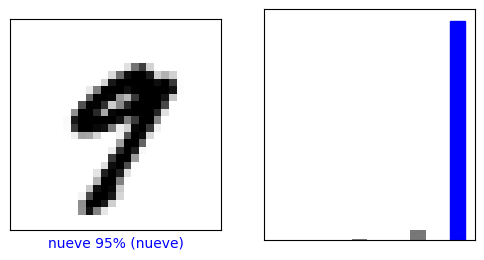

In [14]:
#@title **code** Performance on predictions

i = 20
plt.figure(figsize=(6,3))
plt.subplot(1,2,1)
plot_image(i, predictions, y_test, x_test)
plt.subplot(1,2,2)
plot_value_array(i, predictions,  y_test)

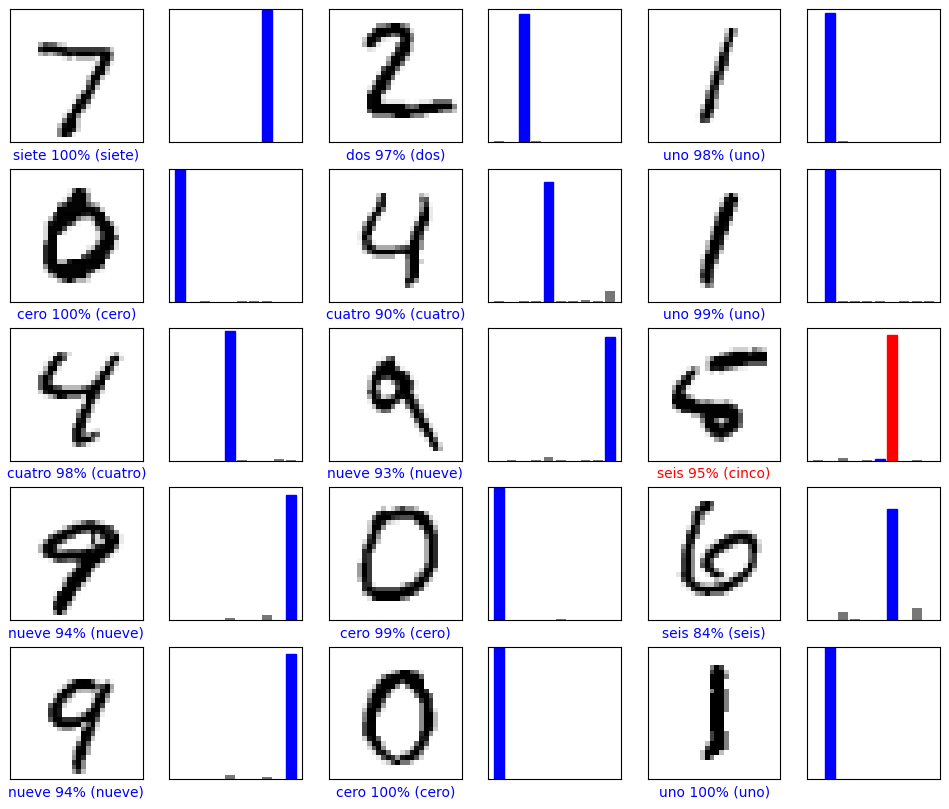

In [15]:
#@title **code** Batch of predictions

num_rows = 5
num_cols = 3
num_images = num_rows*num_cols
plt.figure(figsize=(2*2*num_cols, 2*num_rows))
for i in range(num_images):
    plt.subplot(num_rows, 2*num_cols, 2*i+1)
    plot_image(i, predictions, y_test, x_test)
    plt.subplot(num_rows, 2*num_cols, 2*i+2)
    plot_value_array(i, predictions, y_test)

(10000, 10)
matrix de confusión en test
 [[ 963    0    2    2    0    3    6    2    2    0]
 [   0 1114    4    2    0    1    3    2    9    0]
 [   8    4  957   11   11    1    8   11   15    6]
 [   1    1   18  939    0   13    3   10   16    9]
 [   1    2    4    0  931    0   10    2    4   28]
 [  10    2    3   37    8  788   16    4   15    9]
 [   9    3    4    1   11    9  916    2    3    0]
 [   1    8   23    6    7    0    0  958    2   23]
 [   7    6    5   14    8   10   12    8  897    7]
 [  11    7    1   11   32    4    1   12    2  928]]
verifica número de imágenes en total por fila
[ 980 1135 1032 1010  982  892  958 1028  974 1009]


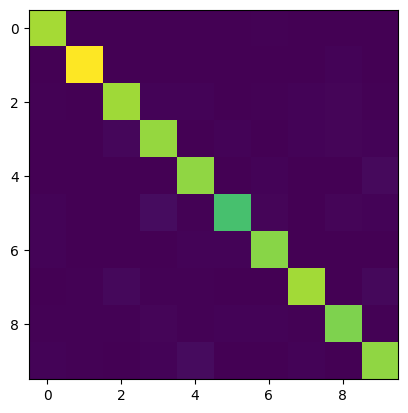

In [16]:
#@title **code** confussion matrices to underestand results
from sklearn.metrics import confusion_matrix
print(predictions.shape)
labels_pred = np.argmax(predictions, axis=1)
cm_test = confusion_matrix(y_test, labels_pred)
print ("matrix de confusión en test\n", cm_test)
print( "verifica número de imágenes en total por fila")
print( np.sum(cm_test, axis=1))
plt.imshow(cm_test)

<img src="https://gitlab.com/bivl2ab/academico/cursos-uis/ai/ai-2-uis-student/-/raw/master/imgs/icon1.png" width="200">


1. Change configuration with two different activation function: tanh, elu
2. Built a deep neural network with:
    - one hidden layer of 512 neurons and relu activation
    - one hidden layers of 128.
3. Try with a more challenge dataset: for instance: **fashion mnist**



In [ ]:
#@title **code student**
#1. point




test_loss, test_acc = model.evaluate(x_test, y_test)

print('Test accuracy:', test_acc)

In [ ]:
#@title **code student**
#2. point





test_loss, test_acc = model.evaluate(x_test, y_test)

print('Test accuracy:', test_acc)

# **References**

[1] Tensorflow: https://www.tensorflow.org/


[2] Playground: http://playground.tensorflow.org/


[3] Udacity deep learning course: https://classroom.udacity.com/courses/ud730

<img src="https://gitlab.com/bivl2ab/academico/cursos-uis/cv/cv-uis-student/raw/master/imgs/bannerThanks.jpg" style="width:1000px;">